# Customer Segmentation Using RFM Analysis

This notebook performs **Recency, Frequency, and Monetary (RFM) Segmentation** on the `Online Retail.xlsx` dataset.

### Pipeline Overview:
1. **Environment Setup & Data Loading**
2. **Data Cleaning & Preprocessing**
3. **RFM Metrics Computation & Scoring (Self-Contained)**
4. **Customer Segmentation Mapping**
5. **Segment Summary Tables & Visualizations**

## 1. Environment Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

# Pandas formatting display options
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Load Online Retail dataset
print("Loading dataset...")
df = pd.read_excel('Online Retail.xlsx')
print(f"Raw Dataset Loaded: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Loading dataset...


Raw Dataset Loaded: 541,909 rows x 8 columns


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.00,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.00,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.00,United Kingdom


## 2. Data Cleaning & Transaction Filtering
Filter out cancellations, rows without Customer IDs, and non-positive quantities or unit prices.

In [2]:
# Drop exact duplicate rows
df_clean = df.drop_duplicates().copy()

# Drop records missing CustomerID or Description
df_clean = df_clean.dropna(subset=['CustomerID', 'Description'])

# Exclude cancellations (InvoiceNo starting with 'C')
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]

# Keep only strictly positive Quantity and UnitPrice
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]

# Format CustomerID as integer
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# Calculate total transaction revenue
df_clean['Revenue'] = (df_clean['Quantity'] * df_clean['UnitPrice']).round(2)

print(f"Cleaned Dataset: {len(df_clean):,} records across {df_clean['CustomerID'].nunique():,} unique customers.")
print(f"Date Range: From {df_clean['InvoiceDate'].min()} to {df_clean['InvoiceDate'].max()}")

Cleaned Dataset: 392,692 records across 4,338 unique customers.
Date Range: From 2010-12-01 08:26:00 to 2011-12-09 12:50:00


## 3. RFM Metrics Computation & Scoring (Quintiles 1 to 5)
- **Snapshot Date:** 1 day after latest transaction date.
- **Recency (R):** Days since last purchase (Score 5 = most recent, 1 = oldest).
- **Frequency (F):** Unique order count (Score 5 = highest frequency, 1 = single order).
- **Monetary (M):** Total spend (Score 5 = highest spend, 1 = lowest spend).

In [3]:
# Reference snapshot date
snapshot_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)
print(f"Analysis Snapshot Date: {snapshot_date}")

# Aggregate per CustomerID
rfm = df_clean.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda date: (snapshot_date - date.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

# Quintile Scoring (1 to 5)
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# Combined RFM representation
rfm['RFM_Group'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)
rfm['RFM_Score'] = rfm[['R_Score', 'F_Score', 'M_Score']].sum(axis=1)

print("RFM Metrics & Scores Computed Successfully:")
display(rfm.head(10))

Analysis Snapshot Date: 2011-12-10 12:50:00


RFM Metrics & Scores Computed Successfully:


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Group,RFM_Score
0,12346,326,1,77183.60,1,1,5,115,7
1,12347,2,7,4310.00,5,5,5,555,15
2,12348,75,4,1797.24,2,4,4,244,10
3,12349,19,1,1757.55,4,1,4,414,9
4,12350,310,1,334.40,1,1,2,112,4
5,12352,36,8,2506.04,3,5,5,355,13
6,12353,204,1,89.00,1,1,1,111,3
7,12354,232,1,1079.40,1,1,4,114,6
8,12355,214,1,459.40,1,1,2,112,4
9,12356,23,3,2811.43,4,3,5,435,12


## 4. Customer Segmentation Mapping
Map (R_Score, F_Score) combinations into standard retail marketing segments.

In [4]:
# Explicit segmentation function guaranteeing all scores are mapped
def assign_rfm_segment(row):
    r = row['R_Score']
    f = row['F_Score']
    if r >= 4 and f >= 4:
        return 'Champions'
    elif r >= 2 and f >= 3:
        return 'Loyal Customers'
    elif r >= 3 and f <= 2:
        return 'Potential Loyalists'
    elif r == 1 and f >= 4:
        return 'At Risk / Can\'t Lose Them'
    elif r == 1 and f in [2, 3]:
        return 'Hibernating'
    elif r == 1 and f == 1:
        return 'Lost / Churned'
    elif r in [2, 3] and f == 1:
        return 'About to Sleep'
    elif r in [2, 3] and f == 2:
        return 'Customers Needing Attention'
    else:
        return 'Promising'

rfm['Segment'] = rfm.apply(assign_rfm_segment, axis=1)

print("Segment Assignment Sample:")
display(rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary', 'RFM_Group', 'Segment']].head(10))

Segment Assignment Sample:


,CustomerID,Recency,Frequency,Monetary,RFM_Group,Segment
0,12346,326,1,77183.60,115,Lost / Churned
1,12347,2,7,4310.00,555,Champions
2,12348,75,4,1797.24,244,Loyal Customers
3,12349,19,1,1757.55,414,Potential Loyalists
4,12350,310,1,334.40,112,Lost / Churned
5,12352,36,8,2506.04,355,Loyal Customers
6,12353,204,1,89.00,111,Lost / Churned
7,12354,232,1,1079.40,114,Lost / Churned
8,12355,214,1,459.40,112,Lost / Churned
9,12356,23,3,2811.43,435,Loyal Customers


## 5. Segment Summary Table

In [5]:
# Aggregate segment-level metrics
segment_summary = rfm.groupby('Segment').agg(
    Customer_Count=('CustomerID', 'count'),
    Total_Revenue=('Monetary', 'sum'),
    Mean_Recency=('Recency', 'mean'),
    Mean_Frequency=('Frequency', 'mean'),
    Mean_Monetary=('Monetary', 'mean')
).reset_index()

segment_summary['Customer_Share_%'] = (segment_summary['Customer_Count'] / len(rfm) * 100).round(2)
segment_summary['Revenue_Share_%'] = (segment_summary['Total_Revenue'] / rfm['Monetary'].sum() * 100).round(2)
segment_summary = segment_summary.sort_values(by='Total_Revenue', ascending=False).reset_index(drop=True)

# Formatted Table for Presentation
table_display = segment_summary.copy()
table_display['Customer_Count'] = table_display['Customer_Count'].apply(lambda x: f"{x:,}")
table_display['Customer_Share_%'] = table_display['Customer_Share_%'].apply(lambda x: f"{x:.2f}%")
table_display['Total_Revenue'] = table_display['Total_Revenue'].apply(lambda x: f"£{x:,.2f}")
table_display['Revenue_Share_%'] = table_display['Revenue_Share_%'].apply(lambda x: f"{x:.2f}%")
table_display['Mean_Recency'] = table_display['Mean_Recency'].apply(lambda x: f"{x:.1f} days")
table_display['Mean_Frequency'] = table_display['Mean_Frequency'].apply(lambda x: f"{x:.1f} orders")
table_display['Mean_Monetary'] = table_display['Mean_Monetary'].apply(lambda x: f"£{x:,.2f}")

print("=" * 95)
print("                         RFM SEGMENTATION SUMMARY TABLE                          ")
print("=" * 95)
display(table_display)

                         RFM SEGMENTATION SUMMARY TABLE                          


,Segment,Customer_Count,Total_Revenue,Mean_Recency,Mean_Frequency,Mean_Monetary,Customer_Share_%,Revenue_Share_%
0,Champions,"1,139","£5,913,422.08",13.3 days,10.0 orders,"£5,191.77",26.26%,66.54%
1,Loyal Customers,"1,263","£1,906,846.89",64.8 days,3.6 orders,"£1,509.78",29.11%,21.46%
2,Potential Loyalists,670,"£306,327.85",36.8 days,1.2 orders,£457.21,15.44%,3.45%
3,Hibernating,442,"£289,038.98",265.0 days,1.5 orders,£653.93,10.19%,3.25%
4,Lost / Churned,364,"£197,805.86",278.7 days,1.0 orders,£543.42,8.39%,2.23%
5,Customers Needing Attention,202,"£110,115.99",118.4 days,1.3 orders,£545.13,4.66%,1.24%
6,About to Sleep,199,"£92,746.19",118.1 days,1.0 orders,£466.06,4.59%,1.04%
7,At Risk / Can't Lose Them,59,"£70,905.05",233.5 days,4.9 orders,"£1,201.78",1.36%,0.80%


## 6. Visualizations: Segment Distributions & Order Dynamics

C:\Users\USER\AppData\Local\Temp\ipykernel_7880\760427270.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_summary.sort_values(by='Customer_Count', ascending=False),


C:\Users\USER\AppData\Local\Temp\ipykernel_7880\760427270.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=segment_summary, y='Segment', x='Total_Revenue', ax=axes[1], palette='flare')


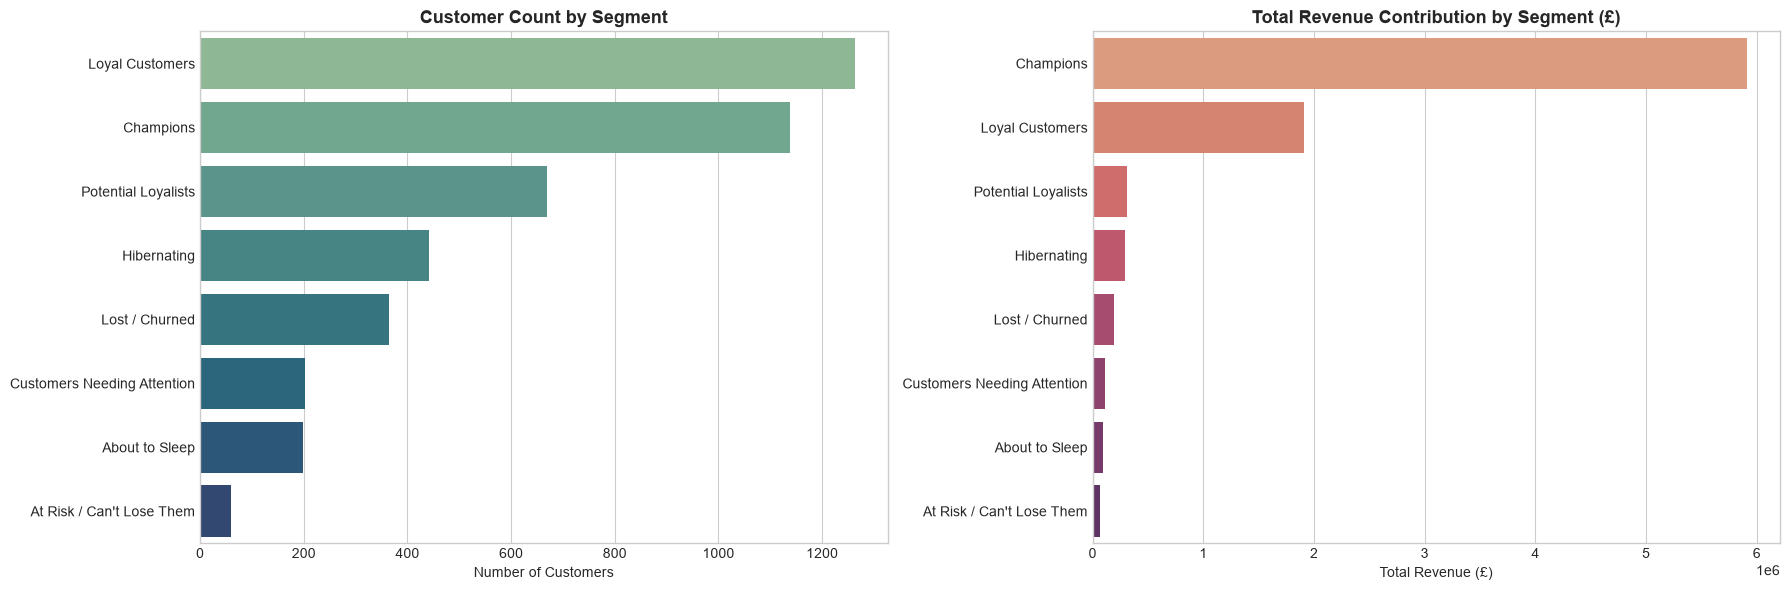

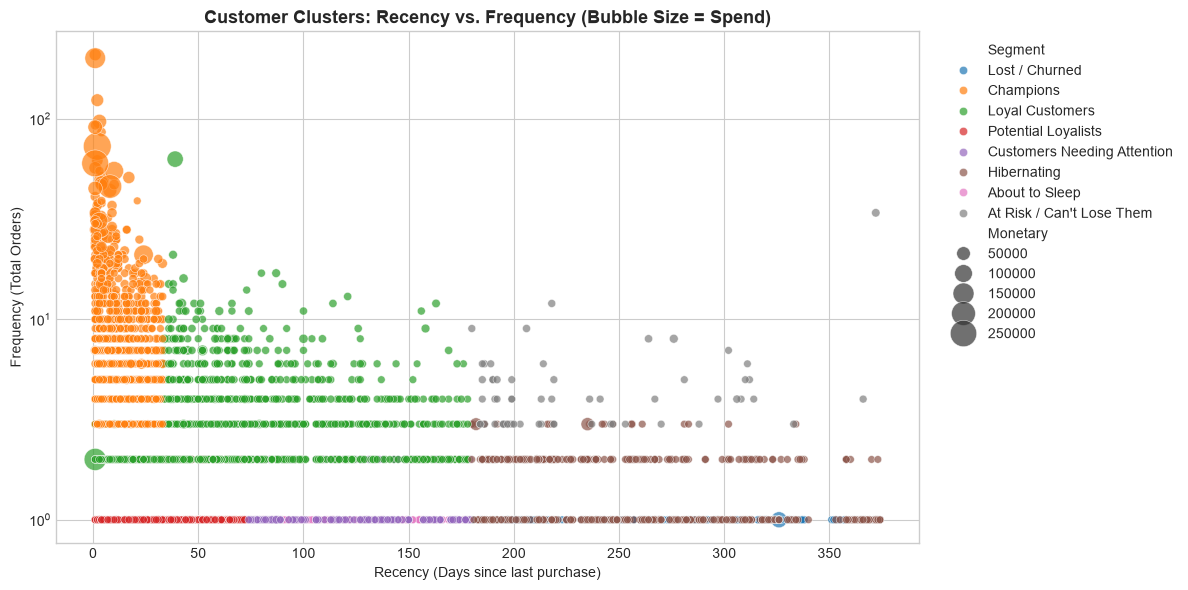

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Customer Count by Segment
sns.barplot(data=segment_summary.sort_values(by='Customer_Count', ascending=False),
            y='Segment', x='Customer_Count', ax=axes[0], palette='crest')
axes[0].set_title('Customer Count by Segment', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Number of Customers')
axes[0].set_ylabel('')

# 2. Total Revenue by Segment
sns.barplot(data=segment_summary, y='Segment', x='Total_Revenue', ax=axes[1], palette='flare')
axes[1].set_title('Total Revenue Contribution by Segment (£)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Total Revenue (£)')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

# 3. Scatter Plot: Recency vs Frequency vs Monetary
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Frequency',
    hue='Segment',
    size='Monetary',
    sizes=(30, 400),
    alpha=0.7,
    palette='tab10'
)
plt.title('Customer Clusters: Recency vs. Frequency (Bubble Size = Spend)', fontsize=13, fontweight='bold')
plt.xlabel('Recency (Days since last purchase)')
plt.ylabel('Frequency (Total Orders)')
plt.yscale('log') # Log scale because a few wholesale outliers have 100+ orders
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()